# 03 — Do the engineered EDA features improve the models?

**Mục tiêu:** thử thêm tám đặc trưng tự tạo (`log_volume`, tương phản trong/ngoài mask, median, IQR, ba kích thước mask và fill ratio), rồi so sánh với pipeline hiện tại trên cùng bệnh nhân và cùng fold.

Run notebooks 01 and 02 first, using the LUNA Radiomics (Python 3.9) kernel. This notebook uses **development patients only**. The existing held-out test predictions, metrics and saved baseline models remain the reference experiment. No new test score or threshold is selected here.

Two comparisons are recorded: add the engineered features while keeping each baseline winner's hyperparameters fixed; then tune the augmented feature sets with the same candidate grid as notebook 02. Report ROC-AUC and MALIGN F1 separately, with F1 at the classifier's default decision rule. Selection still uses ROC-AUC for comparability. These are development CV selection estimates, not an independent final evaluation or a statistical significance test.

## 1. Load the development cohort and freeze the existing experiment

Use the persisted patient/fold assignments rather than drawing a new split. Verify extraction provenance, baseline models and protected artifact hashes. Baseline preprocessing, parameter grids, seeds and fold definitions match notebook 02. No feature statistics or model settings are learned from the test patients.

In [1]:
from pathlib import Path
import os
import json
import hashlib
import importlib.metadata as metadata
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import SimpleITK as sitk
import joblib
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_selection import VarianceThreshold, SelectPercentile, f_classif
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, balanced_accuracy_score, f1_score

ROOT = Path.cwd().resolve()
if not (ROOT / 'MetadatabyNoduleMaxVoting.xlsx').exists() and (ROOT.parent / 'MetadatabyNoduleMaxVoting.xlsx').exists():
    ROOT = ROOT.parent
OUTPUT_SUBDIR = os.environ.get('LUNA_OUTPUT_SUBDIR', '')
assert OUTPUT_SUBDIR in ('', 'smoke')
SMOKE = os.environ.get('LUNA_SMOKE', '0') == '1'
BASE = ROOT / 'artifacts' / OUTPUT_SUBDIR
RAD_OUT, MODEL_OUT = BASE / 'radiomics', BASE / 'modeling'
OUT = BASE / 'feature_engineering'
OUT.mkdir(parents=True, exist_ok=True)
KEYS = ['patient_id', 'nodule_id', 'seriesuid']
SEED = 42
sitk.ProcessObject.SetGlobalDefaultNumberOfThreads(1)

def sha256_file(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

required = ['modeling_dataset.csv', 'split_assignments.csv', 'cv_summary.csv',
            'model_schema.json', 'tabular_best_model.joblib',
            'radiomics_best_model.joblib', 'combined_best_model.joblib']
assert all((MODEL_OUT / name).is_file() for name in required), 'Run notebook 02 first.'
PROTECTED_NAMES = ['split_assignments.csv', 'test_metrics.json', 'test_predictions.csv',
                   'malign_benign_model.joblib', 'model_schema.json',
                   'tabular_best_model.joblib', 'radiomics_best_model.joblib', 'combined_best_model.joblib']
protected_hashes = {name: sha256_file(MODEL_OUT / name) for name in PROTECTED_NAMES}
schema = json.loads((MODEL_OUT / 'model_schema.json').read_text(encoding='utf-8'))
extraction_info = json.loads((RAD_OUT / 'extraction_run.json').read_text(encoding='utf-8'))
assert extraction_info['complete_run'] or (SMOKE and OUTPUT_SUBDIR == 'smoke')
assert schema['split_sha256'] == protected_hashes['split_assignments.csv']
assert schema['extraction_features_sha256'] == sha256_file(RAD_OUT / 'radiomics_features.csv')
assert extraction_info['metadata_sha256'] == sha256_file(ROOT / 'MetadatabyNoduleMaxVoting.xlsx')
assert extraction_info['qc_sha256'] == sha256_file(RAD_OUT / 'qc.csv')
VERSIONS = {name: metadata.version(name) for name in ['numpy', 'pandas', 'scikit-learn', 'SimpleITK', 'joblib']}
for name in VERSIONS:
    assert VERSIONS[name] == schema['versions'][name], f'Baseline environment changed: {name}'

splits = pd.read_csv(MODEL_OUT / 'split_assignments.csv', dtype={'patient_id': str, 'seriesuid': str})
assert splits.groupby('patient_id')['partition'].nunique().max() == 1
development_keys = splits.loc[splits['partition'].eq('development'), KEYS + ['target', 'development_cv_fold']]
all_data = pd.read_csv(MODEL_OUT / 'modeling_dataset.csv', dtype={'patient_id': str, 'seriesuid': str})
assert not all_data.duplicated(KEYS).any() and not development_keys.duplicated(KEYS).any()
dev = all_data.drop(columns=['target']).merge(development_keys, on=KEYS, how='inner', validate='one_to_one').sort_values(KEYS).reset_index(drop=True)
assert len(dev) == len(development_keys)
assert not set(dev['patient_id']) & set(splits.loc[splits['partition'].eq('test'), 'patient_id'])
del all_data  # Subsequent extraction and fitting use only development nodules.
qc = pd.read_csv(RAD_OUT / 'qc.csv', dtype={'patient_id': str, 'seriesuid': str})
dev_qc = dev[KEYS].merge(qc, on=KEYS, how='left', validate='one_to_one')
assert dev_qc['status'].eq('ok').all()
baseline_summary = pd.read_csv(MODEL_OUT / 'cv_summary.csv')
baseline_summary = baseline_summary.loc[baseline_summary['feature_set'].ne('baseline')].copy()
baseline_bundles = {name: joblib.load(MODEL_OUT / f'{name}_best_model.joblib') for name in ['tabular', 'radiomics', 'combined']}
print('Development only:', len(dev), 'nodules /', dev['patient_id'].nunique(), 'patients')

Development only: 786 nodules / 435 patients


## 2. Engineer the eight features from native VOIs and masks

Reproduce the EDA definitions on native images; do not resample these measurements. PyRadiomics remains the existing fixed 1 mm protocol. Orient pairs to LPS before measuring bounding-box axes. LPS versus the EDA's RAS flips signs/directions but does not change these axis extents, voxel counts or intensity summaries.

| Feature | Definition |
|---|---|
| `log_volume` | `log(1 + mask voxel count × voxel volume in mm³)` |
| `intensity_difference` | Mean inside the mask minus mean outside it, within the same VOI |
| `inside_median` | Median stored intensity inside the native mask |
| `inside_iqr` | Native inside-mask intensity percentile 75 minus percentile 25 |
| `mask_size_x_mm`, `mask_size_y_mm`, `mask_size_z_mm` | Inclusive tight bounding-box dimensions in mm, including every labeled component |
| `mask_fill_ratio` | Labeled voxel count divided by tight bounding-box voxel count |

The outside region is the available tissue in the crop, not the whole lung; its mean depends on crop context. Intensity units remain unverified. Some features overlap with radiomics; adding them is a hypothesis to test, not a guaranteed improvement. All definitions are fixed before the comparison and use no diagnosis labels.

In [2]:
ENGINEERED = ['log_volume', 'intensity_difference', 'inside_median', 'inside_iqr',
              'mask_size_x_mm', 'mask_size_y_mm', 'mask_size_z_mm', 'mask_fill_ratio']

def engineer_pair(image_path, mask_path):
    image = sitk.ReadImage(str(image_path), sitk.sitkFloat32)
    mask = sitk.ReadImage(str(mask_path))
    if image.GetDimension() != 3 or mask.GetDimension() != 3 or image.GetSize() != mask.GetSize():
        raise ValueError('Expected matching 3D image/mask dimensions')
    for attr in ['GetSpacing', 'GetOrigin', 'GetDirection']:
        if not np.allclose(getattr(image, attr)(), getattr(mask, attr)(), atol=1e-6, rtol=0):
            raise ValueError('Image/mask geometry mismatch: ' + attr)
    image = sitk.DICOMOrient(image, 'LPS')
    mask = sitk.DICOMOrient(mask, 'LPS')
    values = sitk.GetArrayFromImage(image).astype(np.float64)
    labels = sitk.GetArrayFromImage(mask)
    if not np.isfinite(values).all() or not np.isfinite(labels).all() or not np.isin(labels, [0, 1]).all():
        raise ValueError('Non-finite values or nonbinary mask')
    roi = labels == 1
    if roi.sum() < 8:
        raise ValueError('ROI contains fewer than eight voxels')
    indices = np.argwhere(roi)  # SimpleITK arrays use z, y, x order.
    extents_zyx = np.ptp(indices, axis=0) + 1
    extents_xyz = extents_zyx[::-1]
    sizes_mm = extents_xyz * np.asarray(image.GetSpacing())
    volume_mm3 = float(roi.sum() * np.prod(image.GetSpacing()))
    inside, outside = values[roi], values[~roi]
    q25, q75 = np.percentile(inside, [25, 75])
    return {
        'log_volume': float(np.log1p(volume_mm3)),
        'intensity_difference': float(inside.mean() - outside.mean()) if outside.size else np.nan,
        'inside_median': float(np.median(inside)),
        'inside_iqr': float(q75 - q25),
        'mask_size_x_mm': float(sizes_mm[0]), 'mask_size_y_mm': float(sizes_mm[1]),
        'mask_size_z_mm': float(sizes_mm[2]),
        'mask_fill_ratio': float(roi.sum() / np.prod(extents_xyz)),
    }

feature_rows = []
for _, row in dev_qc.iterrows():
    image_path = ROOT / 'VOIs' / 'VOIs' / 'image' / row['image']
    mask_path = ROOT / 'VOIs' / 'VOIs' / 'nodule_mask' / row['image']
    assert sha256_file(image_path) == row['image_sha256'], 'VOI changed: rerun baseline pipeline first.'
    assert sha256_file(mask_path) == row['mask_sha256'], 'Mask changed: rerun baseline pipeline first.'
    values = engineer_pair(image_path, mask_path)
    np.testing.assert_allclose(values['log_volume'], np.log1p(row['native_volume_mm3']), rtol=1e-8)
    feature_rows.append({**row[KEYS].to_dict(), **values})
engineered = pd.DataFrame(feature_rows)
assert not engineered.duplicated(KEYS).any()
engineered.to_csv(OUT / 'engineered_features_development.csv', index=False)
dev = dev.merge(engineered, on=KEYS, how='left', validate='one_to_one')
assert len(dev) == len(development_keys)
display(dev[ENGINEERED].describe().round(3))
print('Engineered feature missing values:', int(dev[ENGINEERED].isna().sum().sum()))

,log_volume,intensity_difference,inside_median,inside_iqr,mask_size_x_mm,mask_size_y_mm,mask_size_z_mm,mask_fill_ratio
count,786.000,786.000,786.000,786.000,786.000,786.000,786.000,786.000
mean,5.859,367.030,-292.023,416.421,11.973,11.949,10.118,0.415
std,1.396,255.578,229.860,225.211,8.139,8.177,6.273,0.118
min,3.482,-221.853,-800.000,60.500,3.516,3.516,2.500,0.095
25%,4.749,192.228,-462.000,300.312,6.565,6.538,6.000,0.336
50%,5.529,333.378,-298.000,380.000,9.141,8.906,7.500,0.420
75%,6.740,510.852,-122.000,471.750,14.160,14.063,12.500,0.494
max,9.740,1372.828,455.000,1718.000,56.602,58.398,48.750,0.819


Engineered feature missing values: 0


## 3. Reuse exactly the original grouped folds

No new holdout split is drawn. The original persisted validation-fold number defines each split. Every baseline and augmented model uses the same validation patients; assert separation and both labels in every fold.

In [3]:
TAB_NUMERIC = ['diameter_mm', 'Lobulation_value', 'Margin_value', 'Sphericity_value',
               'Spiculation_value', 'Subtlety_value', 'Texture_value']
TAB_CATEGORICAL = ['Calcification_value', 'InternalStructure_value']
RAD_COLUMNS = sorted(c for c in dev if c.startswith('rad_original_'))
assert len(RAD_COLUMNS) == extraction_info['n_features']
FEATURE_SETS = {
    'tabular': (TAB_NUMERIC, TAB_CATEGORICAL),
    'radiomics': (RAD_COLUMNS, []),
    'combined': (TAB_NUMERIC + RAD_COLUMNS, TAB_CATEGORICAL),
}
ALL_COLUMNS = TAB_NUMERIC + TAB_CATEGORICAL + RAD_COLUMNS + ENGINEERED
FORBIDDEN = set(KEYS + ['target', 'Diagnosis', 'Diagnosis_value', 'Malignancy', 'Malignancy_value', 'len_mal_details', 'image'])
assert not FORBIDDEN.intersection(ALL_COLUMNS)
X_dev = dev[ALL_COLUMNS].apply(pd.to_numeric, errors='raise').replace([np.inf, -np.inf], np.nan)
y_dev = dev['target'].astype(int)
groups_dev = dev['patient_id']
fold_numbers = sorted(dev['development_cv_fold'].unique())
assert fold_numbers == list(range(3 if SMOKE else 5))
cv_splits = []
for fold in fold_numbers:
    train = np.flatnonzero(dev['development_cv_fold'].to_numpy() != fold)
    validation = np.flatnonzero(dev['development_cv_fold'].to_numpy() == fold)
    assert not set(groups_dev.iloc[train]) & set(groups_dev.iloc[validation])
    assert y_dev.iloc[train].nunique() == 2 and y_dev.iloc[validation].nunique() == 2
    cv_splits.append((train, validation))
dev[KEYS + ['development_cv_fold']].to_csv(OUT / 'development_folds.csv', index=False)
display(pd.crosstab(dev['development_cv_fold'], dev['Diagnosis']))

Diagnosis,Benign,Malign
development_cv_fold,,
0,95,57
1,95,63
2,123,53
3,84,54
4,106,56


## 4. Compare fixed baseline configurations before/after adding features

First keep each feature set's baseline-winning algorithm and hyperparameters fixed. This comparison separates adding features from searching a new configuration. Recalculate the baseline fold ROC-AUC and assert that it reproduces the saved mean, then record MALIGN F1 as well. F1 here is **development CV**, not the original held-out-test F1 of 85.27%.

In [4]:
def make_pipeline(numeric, categorical, classifier):
    transformers = []
    if numeric:
        transformers.append(('numeric', Pipeline([
            ('impute', SimpleImputer(strategy='median', keep_empty_features=True)),
            ('scale', StandardScaler()),
        ]), numeric))
    if categorical:
        transformers.append(('categorical', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent', keep_empty_features=True)),
            ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
        ]), categorical))
    return Pipeline([
        ('preprocess', ColumnTransformer(transformers, remainder='drop', verbose_feature_names_out=True)),
        ('variance', VarianceThreshold()),
        ('select', SelectPercentile(score_func=f_classif, percentile=100)),
        ('classifier', classifier),
    ])

def evaluate_folds(pipeline):
    rows, probabilities = [], np.full(len(X_dev), np.nan)
    predictions = np.full(len(X_dev), -1)
    for fold, (train, validation) in enumerate(cv_splits):
        estimator = clone(pipeline).fit(X_dev.iloc[train], y_dev.iloc[train])
        probability = estimator.predict_proba(X_dev.iloc[validation])[:, 1]
        prediction = estimator.predict(X_dev.iloc[validation])
        labels = y_dev.iloc[validation]
        probabilities[validation], predictions[validation] = probability, prediction
        rows.append({
            'fold': fold, 'roc_auc': roc_auc_score(labels, probability),
            'average_precision': average_precision_score(labels, probability),
            'balanced_accuracy': balanced_accuracy_score(labels, prediction),
            'f1_malign': f1_score(labels, prediction, zero_division=0),
        })
    assert np.isfinite(probabilities).all() and (predictions >= 0).all()
    return pd.DataFrame(rows), probabilities, predictions

baseline_folds, fixed_folds, fixed_rows = {}, {}, []
for name, (numeric, categorical) in FEATURE_SETS.items():
    bundle = baseline_bundles[name]
    baseline_pipeline = bundle['pipeline']
    before, probabilities, predictions = evaluate_folds(baseline_pipeline)
    original = baseline_summary.loc[(baseline_summary['feature_set'] == name) & (baseline_summary['model'] == bundle['model'])].iloc[0]
    np.testing.assert_allclose(before['roc_auc'].mean(), original['mean_cv_roc_auc'], rtol=1e-10, atol=1e-10)
    baseline_folds[name] = before
    before.to_csv(OUT / f'baseline_folds_{name}.csv', index=False)
    oof = dev[KEYS + ['target', 'development_cv_fold']].copy()
    oof['score_malign'], oof['prediction'] = probabilities, predictions
    oof.to_csv(OUT / f'baseline_oof_{name}.csv', index=False)

    augmented = make_pipeline(numeric + ENGINEERED, categorical, clone(baseline_pipeline.named_steps['classifier']))
    augmented.set_params(select__percentile=baseline_pipeline.named_steps['select'].percentile)
    after, _, _ = evaluate_folds(augmented)
    fixed_folds[name] = after
    after.to_csv(OUT / f'fixed_augmented_folds_{name}.csv', index=False)
    fixed_rows.append({
        'feature_set': name, 'model': bundle['model'],
        'baseline_cv_roc_auc': before['roc_auc'].mean(), 'augmented_cv_roc_auc': after['roc_auc'].mean(),
        'delta_cv_roc_auc': (after['roc_auc'] - before['roc_auc']).mean(),
        'baseline_cv_f1_malign': before['f1_malign'].mean(), 'augmented_cv_f1_malign': after['f1_malign'].mean(),
        'delta_cv_f1_malign': (after['f1_malign'] - before['f1_malign']).mean(),
    })
    print(name, 'fixed configuration ROC-AUC delta:', round(fixed_rows[-1]['delta_cv_roc_auc'], 4))
fixed_comparison = pd.DataFrame(fixed_rows)
fixed_comparison.to_csv(OUT / 'fixed_configuration_comparison.csv', index=False)
display(fixed_comparison.round(4))

tabular fixed configuration ROC-AUC delta: -0.0093


radiomics fixed configuration ROC-AUC delta: -0.0042


combined fixed configuration ROC-AUC delta: 0.0013


,feature_set,model,baseline_cv_roc_auc,augmented_cv_roc_auc,delta_cv_roc_auc,baseline_cv_f1_malign,augmented_cv_f1_malign,delta_cv_f1_malign
0,tabular,random_forest,0.9420,0.9327,-0.0093,0.8281,0.8171,-0.0110
1,radiomics,random_forest,0.9271,0.9229,-0.0042,0.8037,0.8070,0.0033
2,combined,logistic,0.9344,0.9357,0.0013,0.8312,0.8264,-0.0048


## 5. Tune augmented inputs with the same search budget

Add the same eight engineered predictors to tabular, radiomics and combined. Use the original six logistic and eight forest configurations per feature set, class weights, seeds and preprocessing. Rank by ROC-AUC, and record AP, balanced accuracy and F1. Thresholds are not tuned in this experiment.

All learned transformations are fitted inside training folds. Reference: [scikit-learn leakage prevention](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).

In [5]:
def model_candidates():
    return {
        'logistic': (
            LogisticRegression(max_iter=5000, class_weight='balanced', solver='liblinear', random_state=SEED),
            {'select__percentile': [50, 100], 'classifier__C': [0.1, 1.0, 10.0]},
        ),
        'random_forest': (
            RandomForestClassifier(n_estimators=200, class_weight='balanced', n_jobs=1, random_state=SEED),
            {'select__percentile': [50, 100], 'classifier__max_depth': [None, 6], 'classifier__min_samples_leaf': [2, 5]},
        ),
    }

SCORING = {'roc_auc': 'roc_auc', 'average_precision': 'average_precision',
           'balanced_accuracy': 'balanced_accuracy', 'f1_malign': 'f1'}
searches, summary_rows = {}, []
for feature_set, (numeric, categorical) in FEATURE_SETS.items():
    for model_name, (classifier, grid) in model_candidates().items():
        if SMOKE:
            grid = {name: [values[0]] for name, values in grid.items()}
        search = GridSearchCV(
            make_pipeline(numeric + ENGINEERED, categorical, classifier), param_grid=grid,
            scoring=SCORING, refit='roc_auc', cv=cv_splits,
            n_jobs=2, error_score='raise', return_train_score=False,
        )
        search.fit(X_dev, y_dev)
        searches[(feature_set, model_name)] = search
        results = pd.DataFrame(search.cv_results_)
        results.to_csv(OUT / f'cv_grid_{feature_set}_{model_name}.csv', index=False)
        best = results.iloc[search.best_index_]
        summary_rows.append({
            'feature_set': feature_set, 'model': model_name,
            'mean_cv_roc_auc': best['mean_test_roc_auc'], 'std_cv_roc_auc': best['std_test_roc_auc'],
            'mean_cv_average_precision': best['mean_test_average_precision'],
            'mean_cv_balanced_accuracy': best['mean_test_balanced_accuracy'],
            'mean_cv_f1_malign': best['mean_test_f1_malign'], 'std_cv_f1_malign': best['std_test_f1_malign'],
            'best_params': json.dumps(search.best_params_, sort_keys=True),
        })
        print(feature_set, '+ engineered /', model_name, 'ROC-AUC:', round(search.best_score_, 4), 'F1:', round(best['mean_test_f1_malign'], 4))
augmented_summary = pd.DataFrame(summary_rows).sort_values(['mean_cv_roc_auc', 'feature_set', 'model'], ascending=[False, True, True]).reset_index(drop=True)
augmented_summary.to_csv(OUT / 'augmented_cv_summary.csv', index=False)
display(augmented_summary)

tabular + engineered / logistic ROC-AUC: 0.9399 F1: 0.825


tabular + engineered / random_forest ROC-AUC: 0.9327 F1: 0.8171


radiomics + engineered / logistic ROC-AUC: 0.9264 F1: 0.8016


radiomics + engineered / random_forest ROC-AUC: 0.929 F1: 0.8059


combined + engineered / logistic ROC-AUC: 0.9357 F1: 0.8264


combined + engineered / random_forest ROC-AUC: 0.9306 F1: 0.8101


,feature_set,model,mean_cv_roc_auc,std_cv_roc_auc,mean_cv_average_precision,mean_cv_balanced_accuracy,mean_cv_f1_malign,std_cv_f1_malign,best_params
0,tabular,logistic,0.939875,0.016094,0.907014,0.868271,0.824986,0.032008,"{""classifier__C"": 1.0, ""select__percentile"": 100}"
1,combined,logistic,0.935720,0.015256,0.907438,0.868205,0.826366,0.025074,"{""classifier__C"": 0.1, ""select__percentile"": 50}"
2,tabular,random_forest,0.932731,0.013804,0.909930,0.858927,0.817127,0.048605,"{""classifier__max_depth"": 6, ""classifier__min_..."
3,combined,random_forest,0.930609,0.014684,0.901039,0.852028,0.810077,0.041606,"{""classifier__max_depth"": null, ""classifier__m..."
4,radiomics,random_forest,0.929034,0.016903,0.898811,0.850892,0.805869,0.046635,"{""classifier__max_depth"": 6, ""classifier__min_..."
5,radiomics,logistic,0.926359,0.017164,0.889819,0.848485,0.801627,0.037308,"{""classifier__C"": 0.1, ""select__percentile"": 50}"


## 6. Paired comparison, model artifacts and conclusion

Select each augmented feature set's best algorithm by ROC-AUC, then compare with that feature set's baseline winner. A model-family change can contribute to this retuned difference; consult the fixed-configuration table above to distinguish it. Report paired fold differences and the number of folds with higher scores, without treating five overlapping-training folds as independent samples for significance claims.

Feature engineering can raise ROC-AUC while lowering F1 at the default decision rule, or vice versa. No blanket improvement is claimed unless supported by the specified metric. No revised test evaluation is produced. Future final generalization claims require independent evaluation because the original test results have already been seen.

,feature_set,baseline_model,augmented_model,baseline_cv_roc_auc,augmented_cv_roc_auc,delta_cv_roc_auc,baseline_cv_f1_malign,augmented_cv_f1_malign,delta_cv_f1_malign,folds_higher_roc_auc,folds_higher_f1
0,tabular,random_forest,logistic,0.9420,0.9399,-0.0022,0.8281,0.8250,-0.0031,2,2
1,radiomics,random_forest,random_forest,0.9271,0.9290,0.0019,0.8037,0.8059,0.0021,4,3
2,combined,logistic,logistic,0.9344,0.9357,0.0013,0.8312,0.8264,-0.0048,5,1


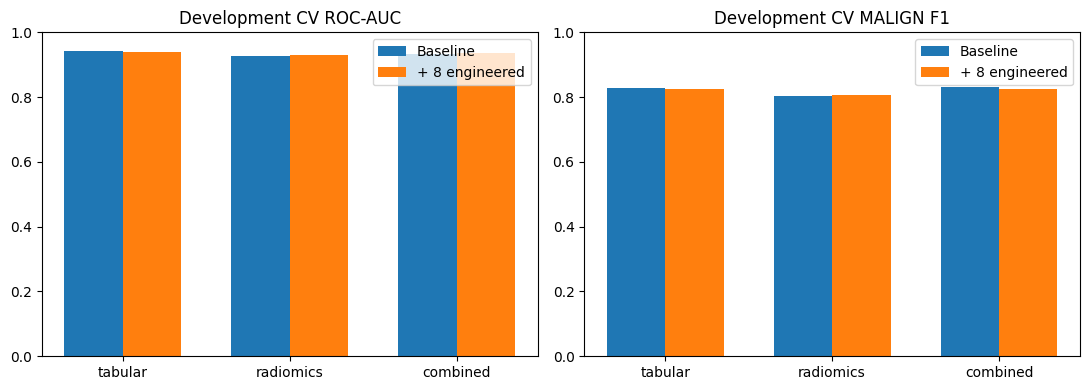

Original test metrics, predictions, splits and baseline models are unchanged.
Artifacts: D:\Github\LUNA-lung-cancer-analysis\artifacts\feature_engineering


In [6]:
comparison_rows, paired_rows = [], []
for feature_set, (numeric, categorical) in FEATURE_SETS.items():
    selected = augmented_summary.loc[augmented_summary['feature_set'].eq(feature_set)].iloc[0]
    search = searches[(feature_set, selected['model'])]
    best = search.cv_results_
    best_idx = search.best_index_
    after = pd.DataFrame({
        'fold': fold_numbers,
        'roc_auc': [best[f'split{fold}_test_roc_auc'][best_idx] for fold in fold_numbers],
        'f1_malign': [best[f'split{fold}_test_f1_malign'][best_idx] for fold in fold_numbers],
    })
    before = baseline_folds[feature_set]
    roc_deltas = after['roc_auc'] - before['roc_auc']
    f1_deltas = after['f1_malign'] - before['f1_malign']
    comparison_rows.append({
        'feature_set': feature_set, 'baseline_model': baseline_bundles[feature_set]['model'],
        'augmented_model': selected['model'],
        'baseline_cv_roc_auc': before['roc_auc'].mean(), 'augmented_cv_roc_auc': after['roc_auc'].mean(),
        'delta_cv_roc_auc': roc_deltas.mean(),
        'baseline_cv_f1_malign': before['f1_malign'].mean(), 'augmented_cv_f1_malign': after['f1_malign'].mean(),
        'delta_cv_f1_malign': f1_deltas.mean(),
        'folds_higher_roc_auc': int(roc_deltas.gt(0).sum()), 'folds_higher_f1': int(f1_deltas.gt(0).sum()),
    })
    for fold in fold_numbers:
        paired_rows.append({'feature_set': feature_set, 'fold': int(fold),
                            'delta_roc_auc': float(roc_deltas.iloc[fold]), 'delta_f1_malign': float(f1_deltas.iloc[fold])})
    fitted = search.best_estimator_
    encoded = np.asarray(fitted.named_steps['preprocess'].get_feature_names_out())
    nonconstant = encoded[fitted.named_steps['variance'].get_support()]
    selected_names = nonconstant[fitted.named_steps['select'].get_support()]
    bundle = {
        'pipeline': fitted, 'required_inputs': numeric + ENGINEERED + categorical,
        'feature_set': feature_set + '_engineered', 'model': selected['model'],
        'engineered_features': ENGINEERED, 'engineering_protocol': 'native-lps-eda-eight-v1',
        'radiomics_protocol_id': extraction_info['protocol_id'],
        'radiomics_params_yaml': (RAD_OUT / 'radiomics_params.yaml').read_text(encoding='utf-8'),
        'selected_features': selected_names.tolist(), 'versions': VERSIONS,
        'label_mapping': {0: 'BENIGN', 1: 'MALIGN'}, 'fitted_partition': 'development',
        'evaluation': 'development_cv_selection_estimate_only',
    }
    path = OUT / f'{feature_set}_engineered_model.joblib'
    joblib.dump(bundle, path)
    restored = joblib.load(path)
    np.testing.assert_allclose(restored['pipeline'].predict_proba(X_dev), fitted.predict_proba(X_dev))
    engineering_selection = pd.DataFrame({'feature': selected_names,
        'engineered': [name.split('__', 1)[-1] in ENGINEERED for name in selected_names]})
    engineering_selection.to_csv(OUT / f'selected_features_{feature_set}.csv', index=False)

comparison = pd.DataFrame(comparison_rows)
comparison.to_csv(OUT / 'retuned_comparison.csv', index=False)
pd.DataFrame(paired_rows).to_csv(OUT / 'paired_fold_differences.csv', index=False)
display(comparison.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
positions, width = np.arange(len(comparison)), 0.35
for ax, metric, title in zip(axes, ['roc_auc', 'f1_malign'], ['Development CV ROC-AUC', 'Development CV MALIGN F1']):
    ax.bar(positions - width / 2, comparison[f'baseline_cv_{metric}'], width, label='Baseline')
    ax.bar(positions + width / 2, comparison[f'augmented_cv_{metric}'], width, label='+ 8 engineered')
    ax.set_xticks(positions, comparison['feature_set'])
    ax.set_ylim(0, 1)
    ax.set_title(title)
    ax.legend()
plt.tight_layout()
plt.savefig(OUT / 'feature_engineering_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

assert protected_hashes == {name: sha256_file(MODEL_OUT / name) for name in PROTECTED_NAMES}, 'A protected baseline artifact changed.'
experiment = {
    'created_at_utc': datetime.now(timezone.utc).isoformat(), 'versions': VERSIONS,
    'development_nodules': len(dev), 'development_patients': dev['patient_id'].nunique(),
    'cv_folds': len(cv_splits), 'engineered_features': ENGINEERED,
    'selection_metric': 'roc_auc', 'threshold_tuned': False, 'test_evaluated': False,
    'smoke_run': SMOKE, 'protected_artifacts_sha256': protected_hashes,
    'radiomics_protocol_id': extraction_info['protocol_id'],
    'engineered_features_sha256': sha256_file(OUT / 'engineered_features_development.csv'),
    'fixed_configuration_comparison': fixed_comparison.to_dict(orient='records'),
    'retuned_comparison': comparison.to_dict(orient='records'),
}
(OUT / 'experiment.json').write_text(json.dumps(experiment, indent=2), encoding='utf-8')

report_lines = [
    '# Kết quả thử thêm feature engineering', '',
    f'Thử tám đặc trưng tự tạo trên {len(dev)} nốt của {dev["patient_id"].nunique()} bệnh nhân development, dùng đúng {len(cv_splits)} fold đã lưu.', '',
    'Các đặc trưng: ' + ', '.join('`' + name + '`' for name in ENGINEERED) + '.', '',
    'Bảng sau so sánh cấu hình tốt nhất trước/sau, cùng ngân sách tìm kiếm và tiêu chí chọn ROC-AUC. F1 là trung bình CV cho MALIGN ở decision rule mặc định, không phải F1 test.', '',
    '| Nhóm | Model trước → sau | AUC trước | AUC sau | Δ AUC | F1 trước | F1 sau | Δ F1 |',
    '|---|---|---:|---:|---:|---:|---:|---:|',
]
for row in comparison.to_dict(orient='records'):
    report_lines.append(
        f'| {row["feature_set"]} | {row["baseline_model"]} → {row["augmented_model"]} | '
        f'{row["baseline_cv_roc_auc"]:.4f} | {row["augmented_cv_roc_auc"]:.4f} | {row["delta_cv_roc_auc"]:+.4f} | '
        f'{row["baseline_cv_f1_malign"]:.4f} | {row["augmented_cv_f1_malign"]:.4f} | {row["delta_cv_f1_malign"]:+.4f} |'
    )
report_lines += ['', 'So sánh giữ nguyên cấu hình baseline trước khi thêm đặc trưng:', '',
                 '| Nhóm | Model cố định | Δ AUC CV | Δ F1 CV |', '|---|---|---:|---:|']
for row in fixed_comparison.to_dict(orient='records'):
    report_lines.append(f'| {row["feature_set"]} | {row["model"]} | {row["delta_cv_roc_auc"]:+.4f} | {row["delta_cv_f1_malign"]:+.4f} |')
report_lines += ['', 'Diễn giải theo từng nhóm:', '']
for row in comparison.to_dict(orient='records'):
    auc_direction = 'tăng' if row['delta_cv_roc_auc'] > 0 else 'giảm' if row['delta_cv_roc_auc'] < 0 else 'không đổi'
    f1_direction = 'tăng' if row['delta_cv_f1_malign'] > 0 else 'giảm' if row['delta_cv_f1_malign'] < 0 else 'không đổi'
    report_lines.append(f'- {row["feature_set"]}: AUC {auc_direction} {abs(row["delta_cv_roc_auc"]):.4f}; F1 {f1_direction} {abs(row["delta_cv_f1_malign"]):.4f}. AUC cao hơn ở {row["folds_higher_roc_auc"]}/{len(cv_splits)} fold; F1 cao hơn ở {row["folds_higher_f1"]}/{len(cv_splits)} fold.')
report_lines += ['', 'Các điểm này là ước lượng CV được dùng để chọn cấu hình; chưa chứng minh khác biệt có ý nghĩa thống kê hoặc khả năng tổng quát hóa trên dữ liệu độc lập. Một số đặc trưng mới chồng lặp với radiomics, nên thêm đặc trưng có thể cải thiện một chỉ số và làm giảm chỉ số khác.', '',
                 'Tập test không được đánh giá lại. Các model và kết quả test ban đầu giữ nguyên, được xác nhận bằng hash. Vì đã xem test trước khi thiết kế thí nghiệm này, một kết luận hiệu năng cuối cùng cho model cải tiến cần đánh giá độc lập.', '',
                 'Biểu đồ so sánh có trong output của [notebook 03](03_feature_engineering_ablation.ipynb). Khi chạy lại, ảnh được lưu vào `artifacts/feature_engineering/feature_engineering_comparison.png`.', '',
                 'Kết quả chi tiết, model và fold differences nằm trong `artifacts/feature_engineering/`. Code và outputs nằm trong `03_feature_engineering_ablation.ipynb`.', '']
report_text = '\n'.join(report_lines)
(OUT / 'FEATURE_ENGINEERING_RESULTS.md').write_text(report_text, encoding='utf-8')
if not SMOKE:
    (ROOT / 'FEATURE_ENGINEERING_RESULTS.md').write_text(report_text, encoding='utf-8')
print('Original test metrics, predictions, splits and baseline models are unchanged.')
print('Artifacts:', OUT)